# AA Results Pipeline

Reusable, results-first notebook for analyzing archetypal analysis output directories.


In [1]:
%load_ext autoreload
%autoreload 2

# Imports
import os
import re
import glob
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from archetypal_analysis.data.loaders import CompendiumDataLoader, ArchetypalResultLoader
from archetypal_analysis.analysis.metrics import AnalysisMetrics
from archetypal_analysis.visualization.simplex import SimplexPlotter
from archetypal_analysis.visualization.composition import CompositionAnalyzer
from archetypal_analysis.visualization.stacked_bar import StackedBarPlotter
from archetypal_analysis.visualization.pcoa import PCoAVisualizer
from archetypal_analysis.utils.metadata import extract_metadata

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.dpi"] = 120


## Config
Edit these values before running the rest of the notebook.


In [2]:
# Required (notebook defaults)
results_dir = "../Extra_Work/outputs/jiaming"   # directory containing otu_AA_K*.json
meta_file = "../Extra_Work/datasets/jiaming_sam.csv"
otu_file_for_composition = "../Extra_Work/datasets/jiaming_otu.tsv"  # must match feature space

selected_k = 6                                             # K to load for detailed analysis
metadata_column = "edu.level"                          # column to color/group by


# Optional compendium metadata sources (set to None if not used)
projects_file = None
tags_file = None

# Optional behavior controls
k_values_for_group_simplex = [4, 7, 11, 13]
pc_combinations = [("PC1", "PC2"), ("PC2", "PC3"), ("PC1", "PC3")]

# Plot settings
simplex_cmap_discrete = "tab10"
simplex_cmap_continuous = "viridis"
stacked_bar_cmap = "tab10"
num_top_taxa = 5
simplified_taxa_level = -1
remove_nan_metadata = True

# Optional ordering (None = keep file order)
archetype_order = None


# Optional dataset config override (similar pattern to final_plots)
# - Set dataset_experiment to a key when using a multi-experiment JSON.
# - Set dataset_config_path to the file for your experiments.
dataset_experiment = "jiaming"
dataset_config_path = "/scratch/rv2340/Archetypal_Analysis_Project/Extra_Work/dataset_config.json"


def _load_json_if_present(path):
    p = Path(path)
    if not p.exists() or p.stat().st_size == 0:
        return None
    with open(p, "r") as f:
        return json.load(f)


def _resolve_experiment_config(raw_config, experiment=None):
    if raw_config is None:
        return {}

    # Case 1: a single-experiment file containing direct config keys.
    if isinstance(raw_config, dict) and "result_dir" in raw_config:
        return raw_config

    # Case 2: a mapping of experiments -> config dict.
    if isinstance(raw_config, dict):
        if experiment is None:
            print("Config file is multi-experiment, but dataset_experiment is None. Using notebook defaults.")
            return {}
        if experiment not in raw_config:
            print(f"Experiment '{experiment}' not found in config. Using notebook defaults.")
            return {}
        if not isinstance(raw_config[experiment], dict):
            raise ValueError(f"Config for experiment '{experiment}' must be a dictionary.")
        return raw_config[experiment]

    raise ValueError("dataset_config JSON must be either a dict of config keys or experiment->config mapping.")


def _pick(config_dict, key, default_value, source_log, default_label="notebook default"):
    if key in config_dict and config_dict[key] is not None:
        source_log[key] = f"dataset config ({dataset_config_path})"
        return config_dict[key]
    source_log[key] = default_label
    return default_value


_config_raw = _load_json_if_present(dataset_config_path)
_cfg = _resolve_experiment_config(_config_raw, dataset_experiment)

_config_source = {}

results_dir = _pick(_cfg, "result_dir", results_dir, _config_source)
meta_file = _pick(_cfg, "meta_file", meta_file, _config_source)
otu_file_for_composition = _pick(_cfg, "otu_file", otu_file_for_composition, _config_source)
selected_k = _pick(_cfg, "main_k", selected_k, _config_source)
metadata_column = _pick(_cfg, "metadata_col", metadata_column, _config_source)

projects_file = _pick(_cfg, "projects_file", projects_file, _config_source)
tags_file = _pick(_cfg, "tags_file", tags_file, _config_source)

k_values_for_group_simplex = _pick(_cfg, "k_values", k_values_for_group_simplex, _config_source)
pc_combinations = _pick(_cfg, "pc_combinations", pc_combinations, _config_source)

simplex_cmap_discrete = _pick(_cfg, "simplex_cmap", simplex_cmap_discrete, _config_source)
simplex_cmap_continuous = _pick(_cfg, "cmap", simplex_cmap_continuous, _config_source)
stacked_bar_cmap = _pick(_cfg, "stacked_bar_cmap", stacked_bar_cmap, _config_source)
num_top_taxa = _pick(_cfg, "num_taxa", num_top_taxa, _config_source)
simplified_taxa_level = _pick(_cfg, "simplified_taxa_level", simplified_taxa_level, _config_source)
remove_nan_metadata = _pick(_cfg, "remove_nan_metadata", remove_nan_metadata, _config_source)
archetype_order = _pick(_cfg, "archetype_order", archetype_order, _config_source)

print("Resolved parameter sources:")
for key, src in _config_source.items():
    print(f"- {key}: {src}")




Resolved parameter sources:
- result_dir: dataset config (/scratch/rv2340/Archetypal_Analysis_Project/Extra_Work/dataset_config.json)
- meta_file: dataset config (/scratch/rv2340/Archetypal_Analysis_Project/Extra_Work/dataset_config.json)
- otu_file: dataset config (/scratch/rv2340/Archetypal_Analysis_Project/Extra_Work/dataset_config.json)
- main_k: notebook default
- metadata_col: notebook default
- projects_file: notebook default
- tags_file: notebook default
- k_values: dataset config (/scratch/rv2340/Archetypal_Analysis_Project/Extra_Work/dataset_config.json)
- pc_combinations: notebook default
- simplex_cmap: notebook default
- cmap: notebook default
- stacked_bar_cmap: notebook default
- num_taxa: notebook default
- simplified_taxa_level: notebook default
- remove_nan_metadata: notebook default
- archetype_order: notebook default


## Utilities


In [3]:
# Helper functions for loading and inference

def discover_result_files(results_directory):
    pattern = os.path.join(results_directory, "otu_AA_K*.json")
    files = glob.glob(pattern)
    k_to_file = {}
    rx = re.compile(r"otu_AA_K(\d+).+\.json$|otu_AA_K(\d+)\.json$")

    for fp in files:
        name = os.path.basename(fp)
        match = rx.search(name)
        if not match:
            continue
        k_str = match.group(1) if match.group(1) is not None else match.group(2)
        k = int(k_str)
        if k not in k_to_file:
            k_to_file[k] = fp

    return dict(sorted(k_to_file.items(), key=lambda x: x[0]))


def load_results_dict(k_to_file):
    loader = ArchetypalResultLoader()
    results = {}
    for k, fp in k_to_file.items():
        try:
            results[k] = loader.load_result(fp)
        except FileNotFoundError:
            print(f"Warning: Missing result for K={k}: {fp}")
    return results


def infer_legend_type(metadata_df, col):
    series = metadata_df[col]
    numeric_series = pd.to_numeric(series, errors="coerce")
    n_valid_numeric = numeric_series.notna().sum()

    if n_valid_numeric > 0:
        return "continuous", numeric_series
    return "discrete", series


def load_metadata_auto(meta_path, projects_path=None, tags_path=None):
    loader = CompendiumDataLoader()
    _, projects, tags, meta = loader.load_all(
        otu_file=None,
        projects_file=projects_path,
        tags_file=tags_path,
        meta_file=meta_path,
    )
    return projects, tags, meta

# Drop nan from metadata column
def drop_nan_from_metadata(metadata_df, col):
    before_count = metadata_df.shape[0]
    metadata_df = metadata_df.dropna(subset=[col])
    after_count = metadata_df.shape[0]
    print(f"Dropped {before_count - after_count} samples with NaN in '{col}'. Remaining samples: {after_count}.")
    return metadata_df


def build_metadata_for_samples(sample_index, metadata_col, meta, projects=None, tags=None):
    md = extract_metadata(
        index=sample_index,
        tags=tags,
        sample_meta=meta,
        projects=projects,
        extract_cols=[metadata_col],
        verbose=False,
    )
    return md


def reorder_similarity_and_archetypes(otu_aa, aa_archetypes, order_cols=None):
    if order_cols is None:
        return otu_aa.copy(), np.array(aa_archetypes)

    missing = [c for c in order_cols if c not in otu_aa.columns]
    if missing:
        raise ValueError(
            f"archetype_order contains columns not present in result: {missing}. "
            f"Available columns: {list(otu_aa.columns)}"
        )

    reordered = otu_aa[order_cols].copy()
    renamed_cols = [f"Archetype {i+1}" for i in range(len(order_cols))]
    reordered.columns = renamed_cols

    idx = [int(c.split()[-1]) - 1 for c in order_cols]
    aa_reordered = np.array(aa_archetypes)[idx, :]
    return reordered, aa_reordered



## Discover Results and Load Selected K


In [4]:
result_loader = ArchetypalResultLoader()

k_to_file = discover_result_files(results_dir)
if len(k_to_file) == 0:
    raise FileNotFoundError(f"No result files matching otu_AA_K*.json found in: {results_dir}")

print("Discovered K values:", list(k_to_file.keys()))

results_dict = load_results_dict(k_to_file)
available_k = sorted(results_dict.keys())
print("Loaded results for K:", available_k)

if selected_k not in results_dict:
    raise ValueError(
        f"selected_k={selected_k} not found. Available K values: {available_k}"
    )

selected_file = k_to_file[selected_k]
otu_aa, aa_labels, aa_archetypes, info = result_loader.load_parsed_result(selected_file)
otu_aa, aa_archetypes = reorder_similarity_and_archetypes(
    otu_aa, aa_archetypes, archetype_order
)
if archetype_order is not None:
    print(f"Applied archetype_order: {archetype_order}")
print(f"Loaded selected result: K={selected_k} from {selected_file}")
print("Similarity degree shape:", otu_aa.shape)



Discovered K values: [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
Loaded results for K: [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
Loaded selected result: K=6 from /scratch/rv2340/Archetypal_Analysis_Project/Extra_Work/outputs/jiaming/otu_AA_K6_1.0.json
Similarity degree shape: (2402, 6)


## Load Metadata and Auto-Detect Metadata Type


In [5]:
projects, tags, meta = load_metadata_auto(
    meta_path=meta_file,
    projects_path=projects_file,
    tags_path=tags_file,
)

metadata = build_metadata_for_samples(
    sample_index=otu_aa.index,
    metadata_col=metadata_column,
    meta=meta,
    projects=projects,
    tags=tags,
)

metadata = drop_nan_from_metadata(metadata, metadata_column)

legend_type, maybe_numeric = infer_legend_type(metadata, metadata_column)
print(f"Metadata column '{metadata_column}' inferred as: {legend_type}")
print(metadata[metadata_column].head())
legend_type="discrete"

Dropped 54 samples with NaN in 'edu.level'. Remaining samples: 2348.
Metadata column 'edu.level' inferred as: continuous
as11798_L20230308_Plate_09-1_A11_S177_R1_001.fastq.gz    2.0
as11798_L20230308_Plate_09-1_B10_S170_R1_001.fastq.gz    3.0
as11798_L20230308_Plate_23-1_E05_S133_R1_001.fastq.gz    3.0
as11798_L20230308_Plate_23-1_C02_S107_R1_001.fastq.gz    3.0
as11798_L20230308_Plate_27-1_F11_S566_R1_001.fastq.gz    3.0
Name: edu.level, dtype: float64


## Metrics Across All K (Silhouette + Davies-Bouldin)


Evaluating K: 100%|██████████| 11/11 [00:01<00:00,  9.63it/s]


,silhouette,davies_bouldin,k
0,-0.107355,21.624733,3
1,-0.048574,27.161122,4
2,-0.049269,26.268995,5
3,-0.055413,19.383579,6
4,-0.031357,19.349938,7
5,-0.068584,19.614224,8
6,-0.034817,19.900202,9
7,-0.037653,24.857258,10
8,-0.049394,22.473000,11
9,-0.041801,22.907330,12


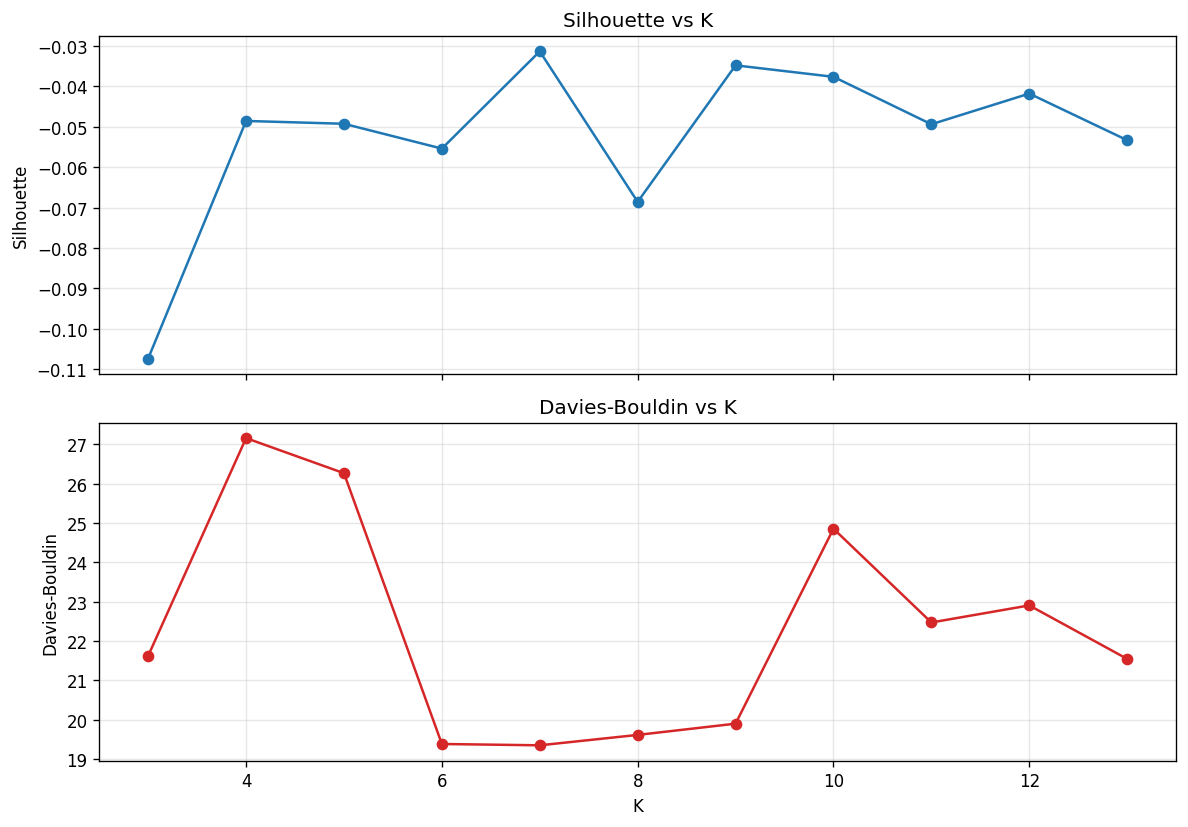

In [6]:
analysis_metrics = AnalysisMetrics()

comparison_df = analysis_metrics.compare_archetype_quality(
    results_dict=results_dict,
    metadata=metadata,
    metadata_column=metadata_column,
    discretize=False,
    buckets=None,
    metrics=["silhouette", "davies_bouldin"],
    drop_nan=True
)

display(comparison_df)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(comparison_df["k"], comparison_df["silhouette"], marker="o")
axes[0].set_title("Silhouette vs K")
axes[0].set_ylabel("Silhouette")
axes[0].grid(True, alpha=0.3)

axes[1].plot(comparison_df["k"], comparison_df["davies_bouldin"], marker="o", color="tab:red")
axes[1].set_title("Davies-Bouldin vs K")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Davies-Bouldin")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Simplex for Selected K (Auto Continuous/Discrete)


/scratch/rv2340/Archetypal_Analysis_Project/Archetypal-Analysis/archetypal_analysis/visualization/simplex.py:176: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filter_labels = filter_labels.fillna(metadata.loc[index, col])


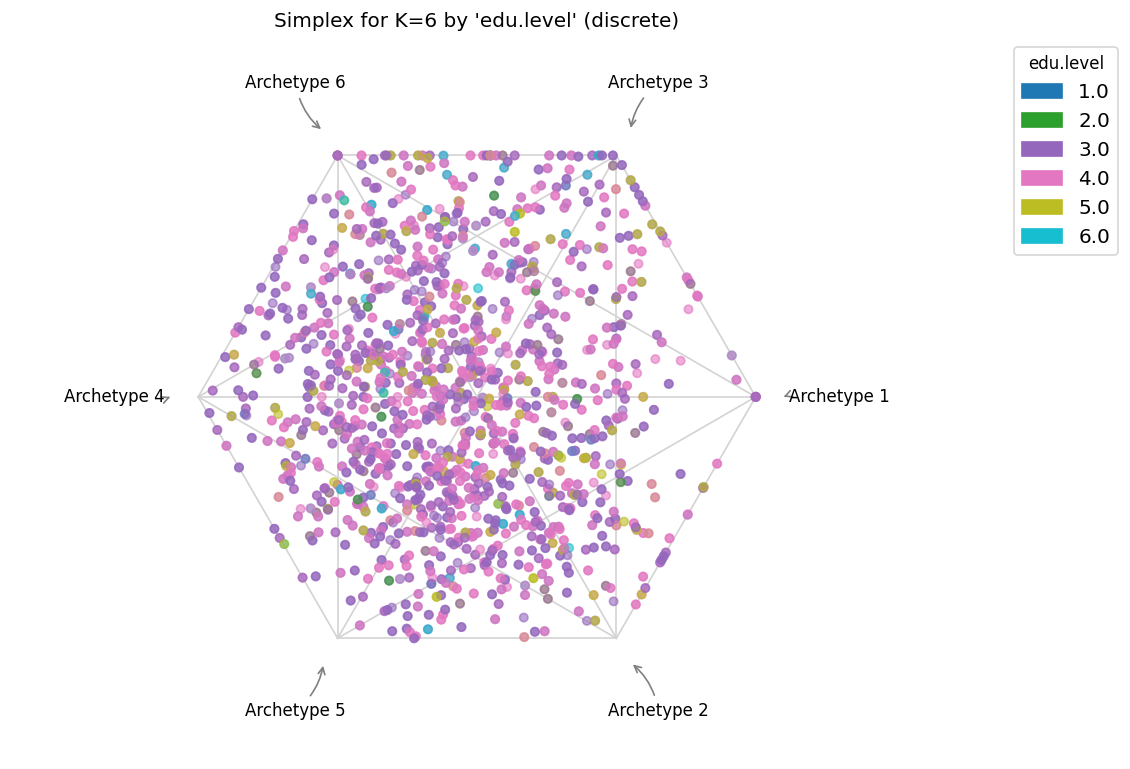

In [12]:
simplex_plotter = SimplexPlotter()
chosen_cmap = simplex_cmap_continuous if legend_type == "continuous" else simplex_cmap_discrete
otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 3", "Archetype 6", "Archetype 4", "Archetype 5", "Archetype 2"]]

simplex_plotter.plot_simplex(
    otu_aa=otu_aa_swapped,
    metadata=metadata,
    filter_cols=[metadata_column],
    cmap_name=chosen_cmap,
    legend_type=legend_type,
    remove_nan=remove_nan_metadata,
    alpha=0.6,
    s=25,
    figsize=(10, 8),
)
plt.title(f"Simplex for K={selected_k} by '{metadata_column}' ({legend_type})")
plt.show()


## Archetype Composition (Stacked Bars via `CompositionAnalyzer`)


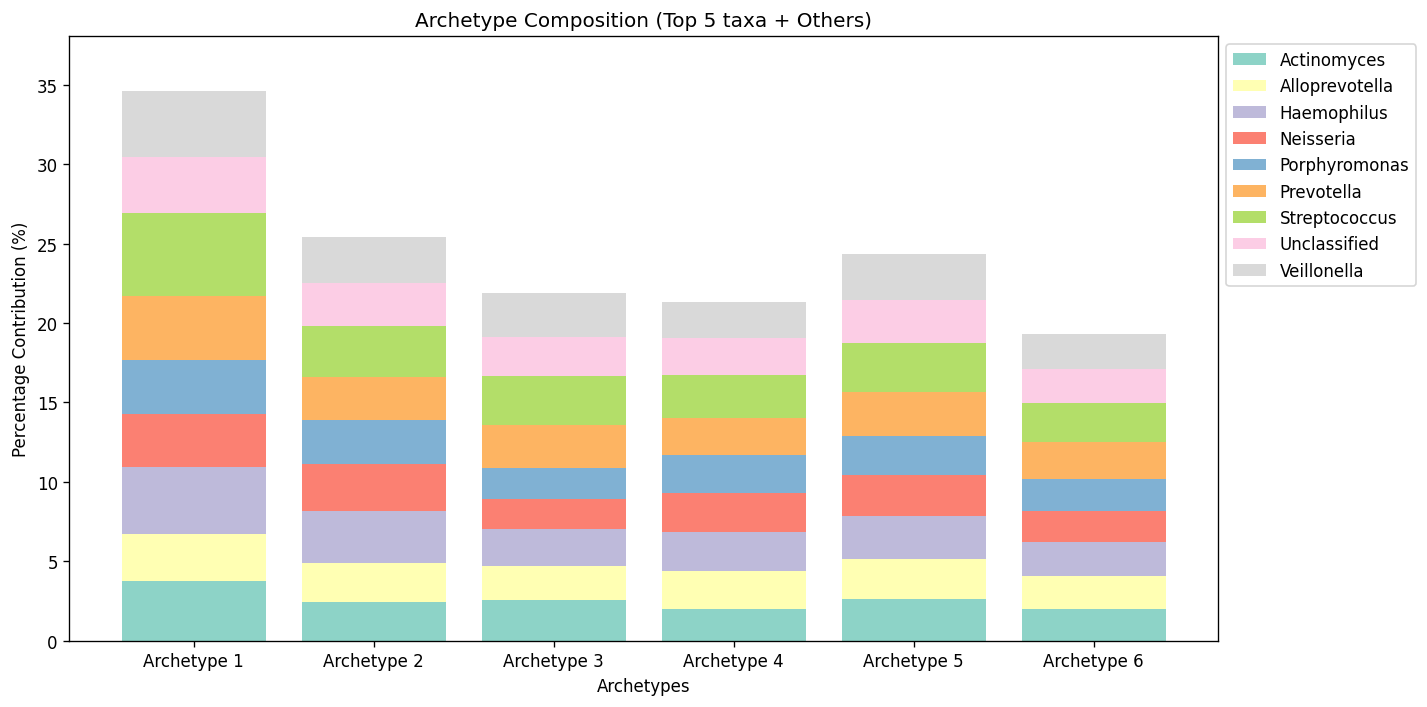

In [8]:
comp_loader = CompendiumDataLoader()
otu_for_composition = comp_loader.load_df(otu_file_for_composition, index_col=0)
new_columns = []
for col in otu_for_composition.columns:
    segments = col.split(".")
    if segments[-1].isdigit():
        # Find the last segment that is not a number
        for i in range(len(segments) - 2, -1, -1):
            if not segments[i].isdigit():
                new_columns.append(".".join(segments[:i + 1])+ f"{segments[-1]}")  # Append the index of the last non-numeric segment
                break
        else:
            new_columns.append(col)  # If all segments are numbers, keep original
    else:
        new_columns.append(col)    
otu_for_composition.columns = new_columns

# Align feature names count with archetype width when possible
if otu_for_composition.shape[1] != np.array(aa_archetypes).shape[1]:
    raise ValueError(
        "OTU feature count does not match archetype feature count. "
        "Please provide an OTU file aligned to the selected result feature space."
    )

composition_analyzer = CompositionAnalyzer()

top_taxa_archs = composition_analyzer.analyze_top_taxa(
    archetypes=np.array(aa_archetypes),
    feature_names=otu_for_composition.columns.tolist(),
    num_taxa=num_top_taxa,
)

composition_analyzer.plot_stacked_bar_chart(
    aa_archetypes=np.array(aa_archetypes),
    feature_names=otu_for_composition.columns.tolist(),
    top_taxa_archetypes=top_taxa_archs,
    figsize=(12, 6),
    sort_by_contribution=False,
    simplified_taxa_level=8,
)
plt.title(f"Archetype Composition (Top {num_top_taxa} taxa + Others)")
plt.show()


## Sample-Level Archetype Mixtures (StackedBarPlotter)


IndexError: index 2359 is out of bounds for axis 0 with size 2348

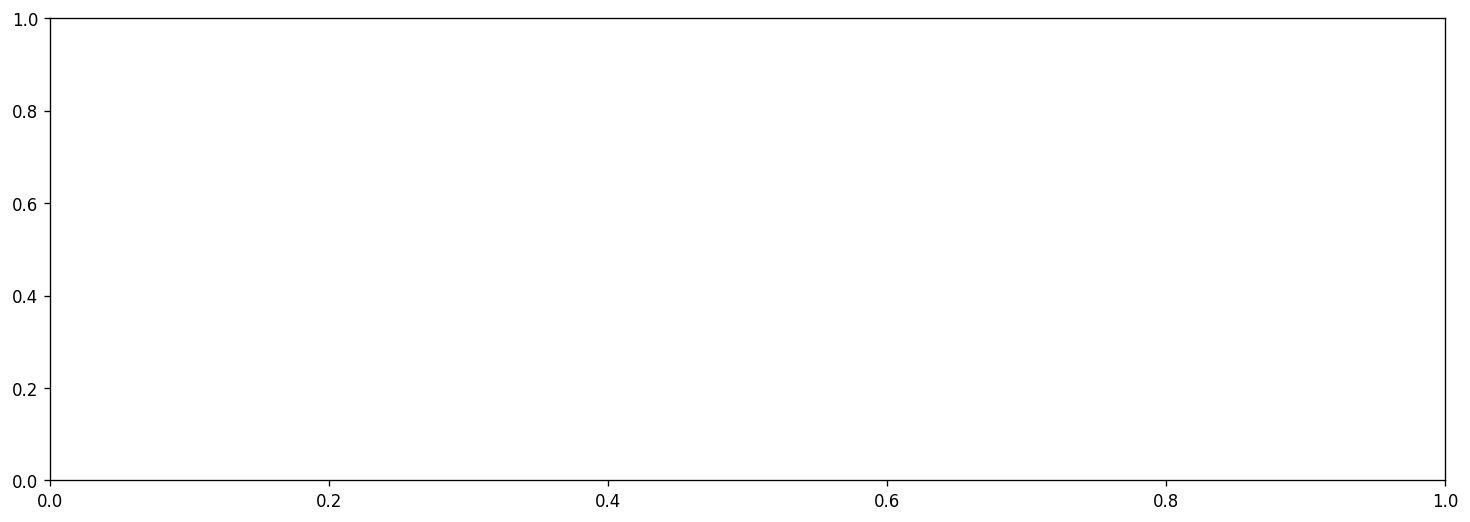

In [9]:
stacked_bar_plotter = StackedBarPlotter()

_ = stacked_bar_plotter.plot_metadata_stacked_bars(
    similarity_degree=otu_aa,
    metadata=metadata,
    metadata_column=metadata_column,
    perms=info.get("perms", None),
    discretize=False,
    buckets=None,
    figsize=(15, 5),
    cmap_name=stacked_bar_cmap,
)
plt.title(f"Sample Archetype Mixtures for K={selected_k} grouped by '{metadata_column}'")
plt.show()


## Extras: Group Simplex for Multiple K


  0%|          | 0/6 [00:00<?, ?it/s]/scratch/rv2340/Archetypal_Analysis_Project/Archetypal-Analysis/archetypal_analysis/visualization/simplex.py:176: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filter_labels = filter_labels.fillna(metadata.loc[index, col])
/scratch/rv2340/Archetypal_Analysis_Project/Archetypal-Analysis/archetypal_analysis/visualization/simplex.py:176: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filter_labels = filter_labels.fillna(metadata.loc[index, col])
 33%|███▎      | 2/6 [00:00<00:00,  9.88it/s]

/scratch/rv2340/Archetypal_Analysis_Project/Archetypal-Analysis/archetypal_analysis/visualization/simplex.py:176: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filter_labels = filter_labels.fillna(metadata.loc[index, col])
 50%|█████     | 3/6 [00:00<00:00,  9.54it/s]/scratch/rv2340/Archetypal_Analysis_Project/Archetypal-Analysis/archetypal_analysis/visualization/simplex.py:176: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filter_labels = filter_labels.fillna(metadata.loc[index, col])
 67%|██████▋   | 4/6 [00:00<00:00,  9.03it/s]/scratch/rv2340/Archetyp

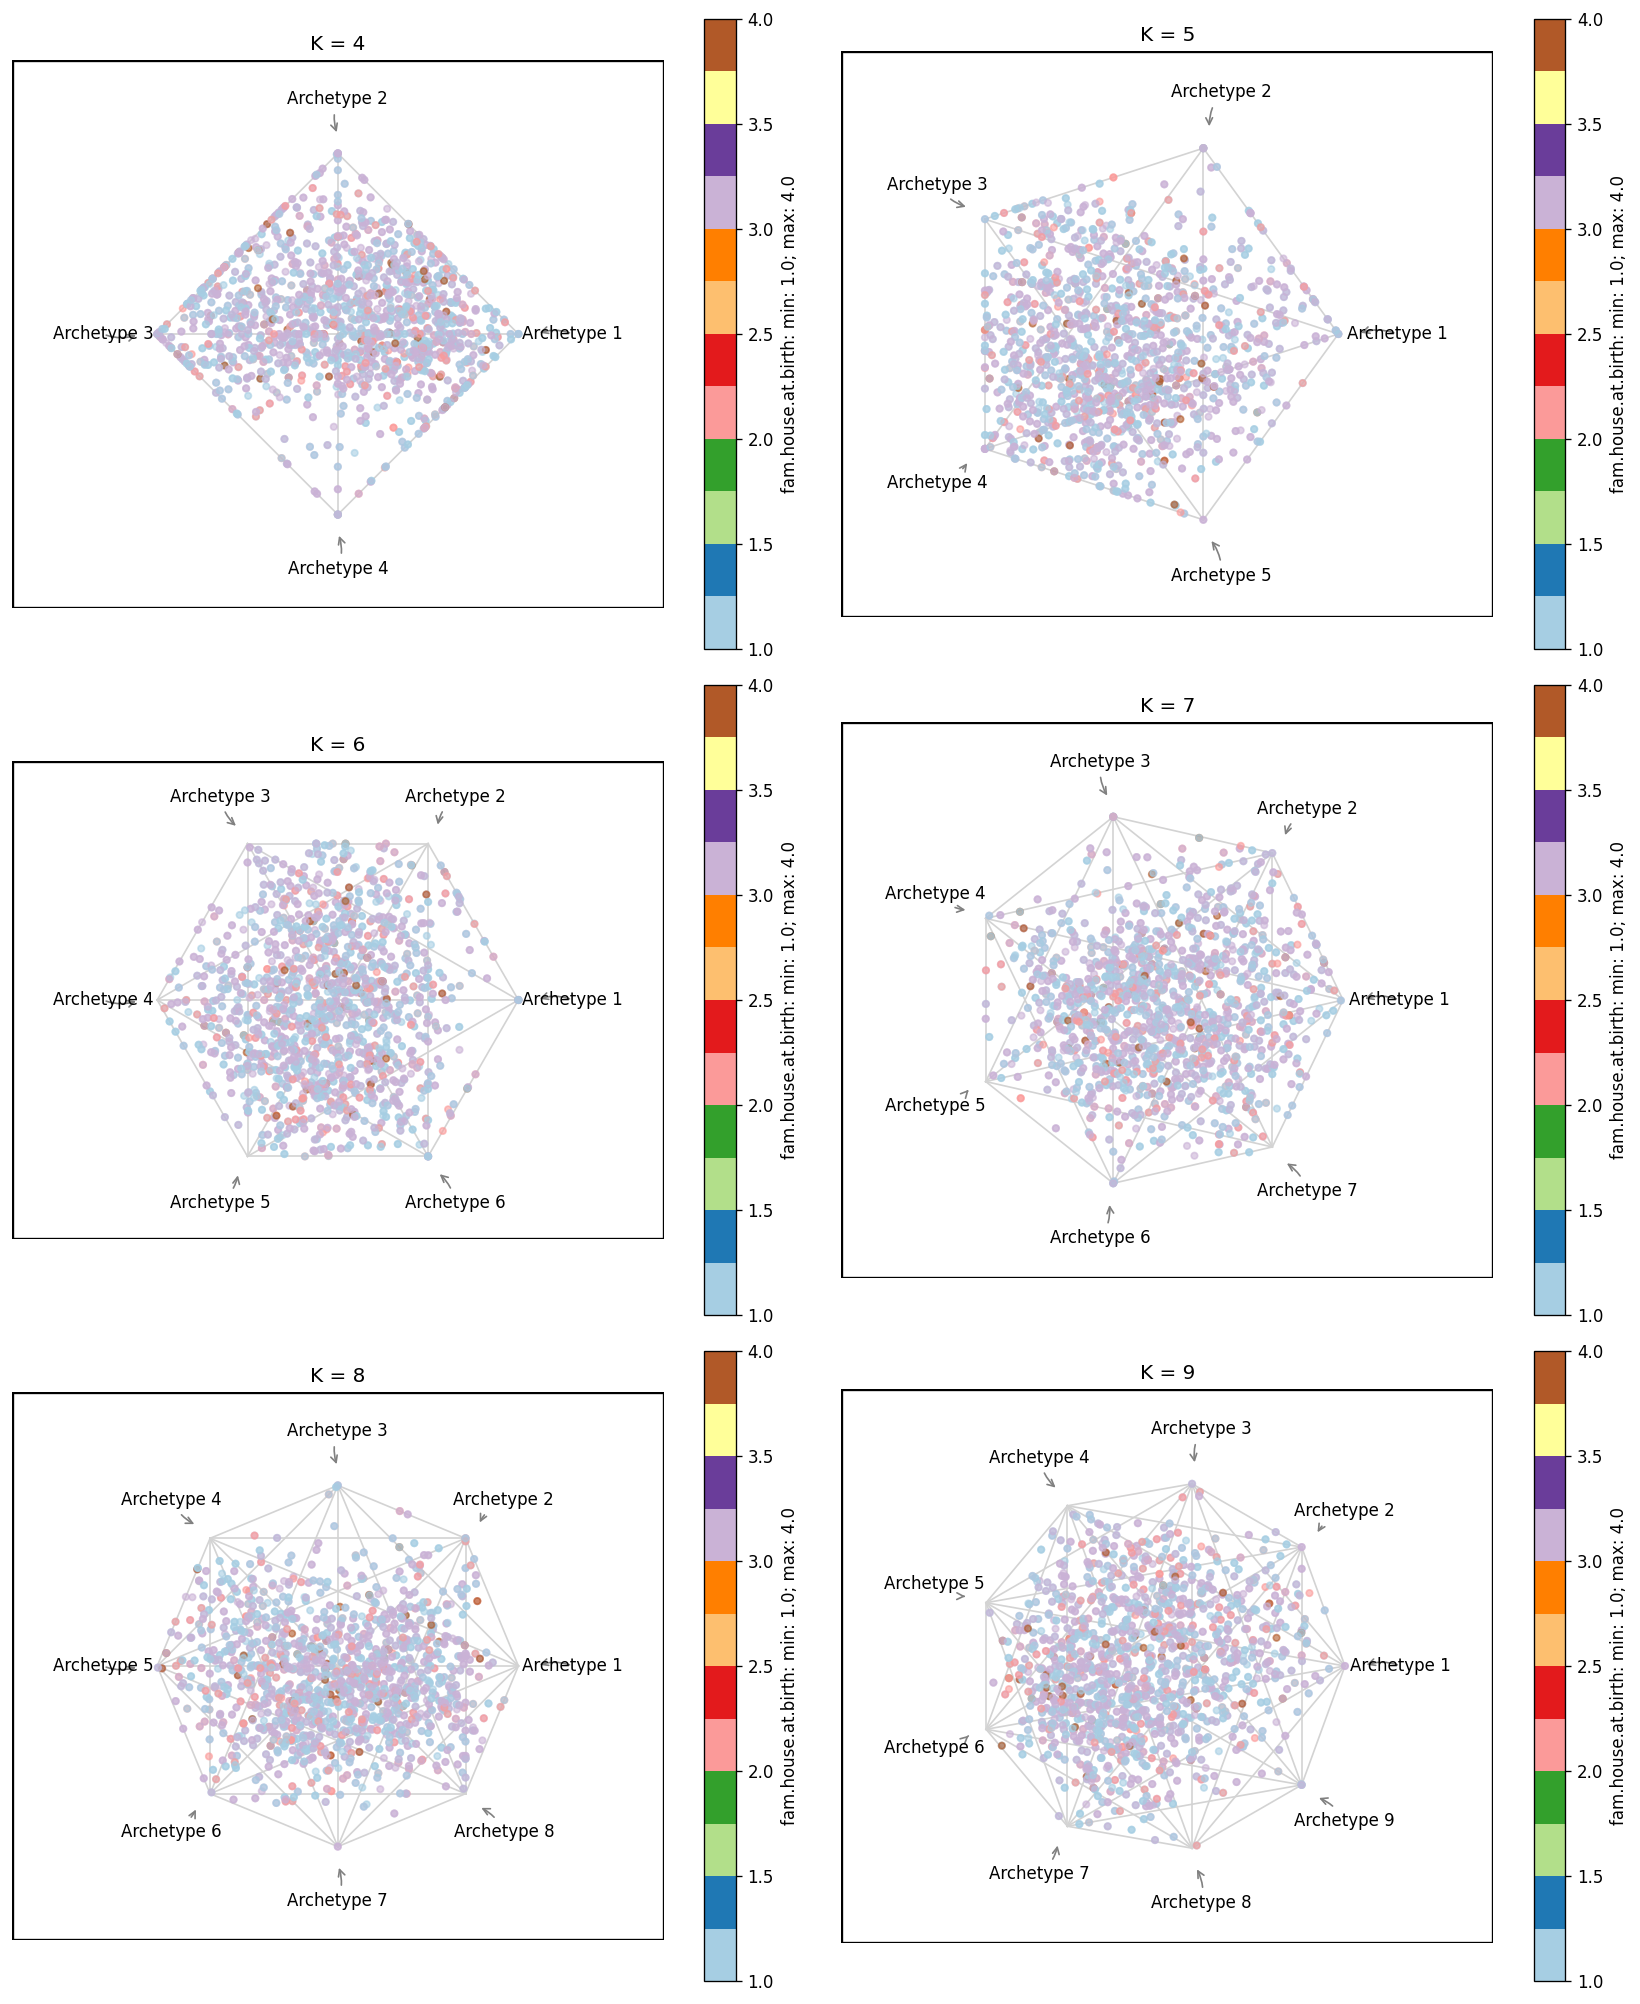

In [ ]:
k_values_present = [4,5,6,7,8,9]
k_values_missing = [k for k in k_values_for_group_simplex if k not in k_to_file]

if len(k_values_missing) > 0:
    print("Warning: Missing K values (skipping):", k_values_missing)

if len(k_values_present) == 0:
    print("No requested K values were found. Nothing to plot.")
else:
    simplex_plotter = SimplexPlotter()
    legend_for_group = legend_type
    cmap_for_group = "Paired"

    # plot_group_simplex expects projects/meta/tags and handles file loading internally
    simplex_plotter.plot_group_simplex(
        directory=results_dir,
        k_values=k_values_present,
        filter_cols=[metadata_column],
        legend_type=legend_for_group,
        projects=projects,
        meta=meta,
        tags=tags,
        swapped_cols=None,
        remove_values={},
        cmap_name=cmap_for_group,
        alpha=0.6,
        s=15,
        plot_size=(7, 7),
        legend_fontsize=9,
        file_template="otu_AA_K{k}_1.0.json",
    )
    plt.show()


## Extras: PCA Plot for User-Defined PC Combinations


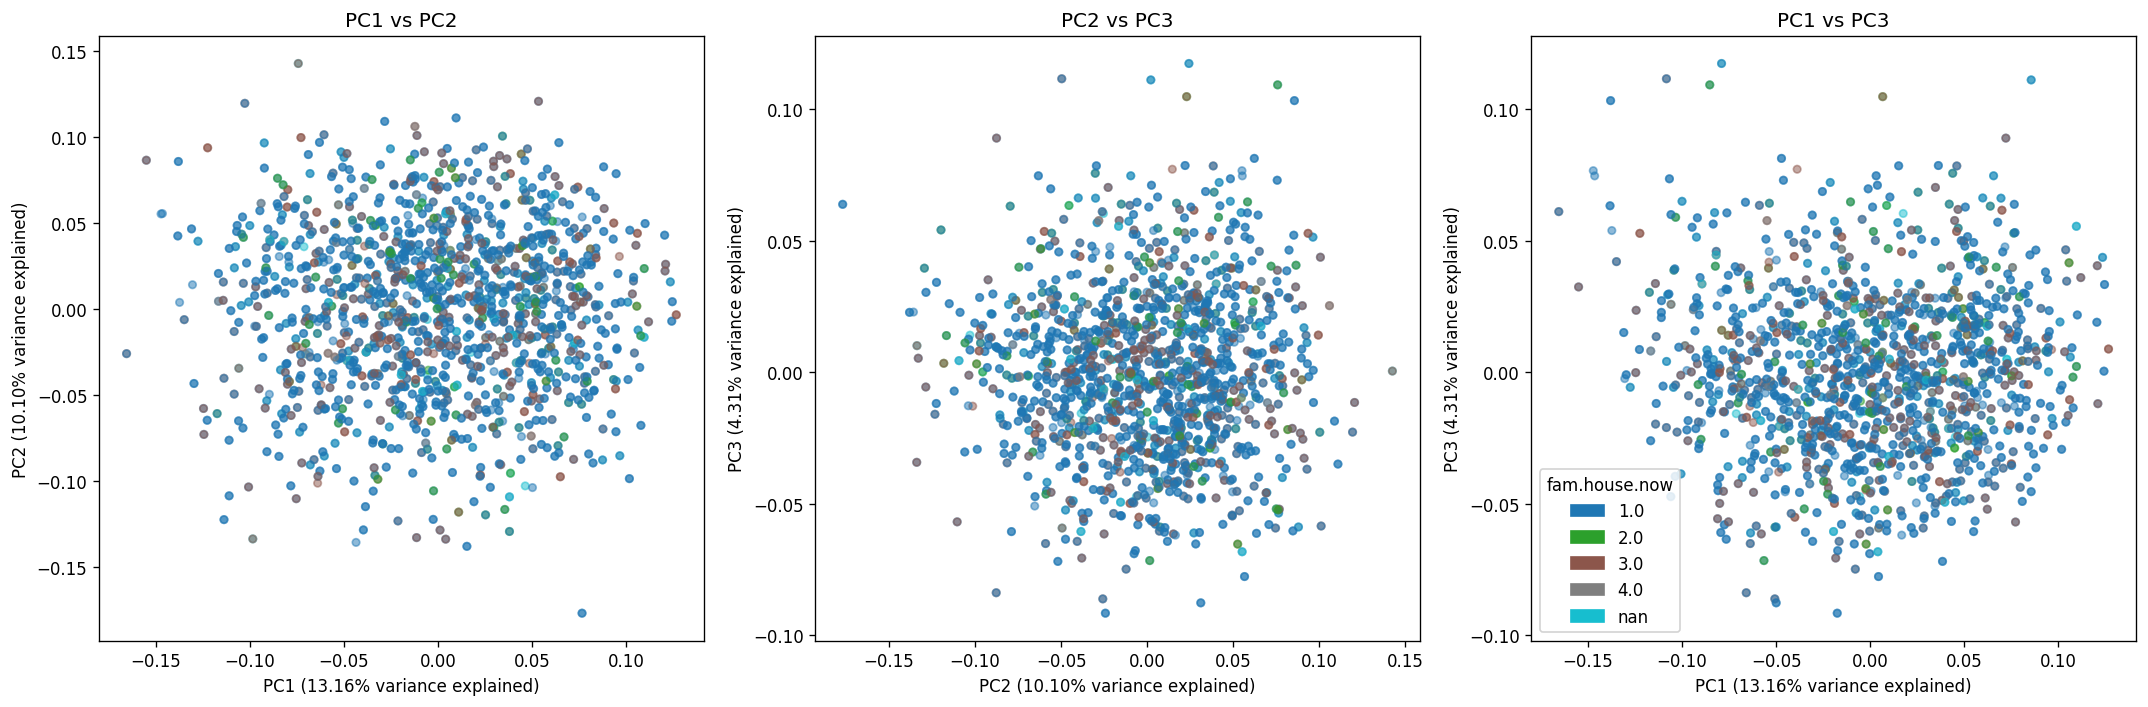

In [ ]:
if True: # PCA/PCoA uses the OTU data and metadata for the same metadata column
    pcoa_visualizer = PCoAVisualizer()

    # Ensure metadata index aligns with OTU rows used for PCoA
    pcoa_metadata = build_metadata_for_samples(
        sample_index=otu_for_composition.index,
        metadata_col=metadata_column,
        meta=meta,
        projects=projects,
        tags=tags,
    )

    pcoa_coords, pcoa_results = pcoa_visualizer.create_pcoa_from_otu(
        otu_data=otu_for_composition,
        distance_metric="jensenshannon",
        n_dimensions=5,
        apply_log_transform=True,
        clean_data=True,
        verbose=False,
    )

    _ = pcoa_visualizer.plot_pcoa(
        pcoa_coordinates=pcoa_coords,
        pcoa_results=pcoa_results,
        metadata=pcoa_metadata,
        filter_col=metadata_column,
        legend_type=legend_type,
        pc_combinations=pc_combinations,
        cmap_name=(simplex_cmap_continuous if legend_type == "continuous" else simplex_cmap_discrete),
        s=20,
    )
    plt.show()


## Smoke Test Checklist
- Run all cells top-to-bottom with one known results directory.
- Verify warnings appear for missing K values without stopping execution.
- Try both numeric and categorical `metadata_column` values.
- Confirm all expected figures render.
